# XAI Lab: Visual explanations


Complete the coding exercises below.

The dataset we will be using is **DermaMNIST**, a subset of the MedMNIST benchmark derived from the HAM10000 collection of dermatoscopic images. It contains skin lesion images across 7 diagnostic categories (e.g., melanoma, nevus, basal cell carcinoma). Each image is a 3-channel RGB photo of a skin lesion, resized to 28×28 pixels in the original benchmark (we upscale to 128×128 here). We will train a CNN classifier on this dataset and apply various saliency-based attribution methods to explain its predictions.

In [1]:
!pip install medmnist
!pip install captum --no-deps
!pip install opencv


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
ERROR: Could not find a version that satisfies the requirement opencv (from versions: none)

[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for opencv


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import torch.nn.functional as F

import medmnist
from medmnist import INFO
from medmnist.dataset import DermaMNIST

from captum.attr import Saliency, NoiseTunnel, LayerGradCam, LayerAttribution, LRP
import cv2

# Check for Apple Silicon GPU (mps), then CUDA, then CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


In [3]:
data_flag = 'dermamnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

# Transform (resize - optional)
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# Load datasets
train_dataset = DataClass(split='train', transform=transform, download=True, size=128)
val_dataset   = DataClass(split='val',   transform=transform, download=True, size=128)
test_dataset  = DataClass(split='test',  transform=transform, download=True, size=128)

# Build loaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)


Using downloaded and verified file: /Users/jonas/.medmnist/dermamnist_128.npz
Using downloaded and verified file: /Users/jonas/.medmnist/dermamnist_128.npz
Using downloaded and verified file: /Users/jonas/.medmnist/dermamnist_128.npz


In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
            )

        self.conv1 = block(3, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = block(32, 64)
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = block(64, 128)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.pool2(x)
        x = self.conv3(x)
        x_gap = self.gap(x).view(x.size(0), -1)
        out = self.fc(x_gap)
        return out

model = SimpleCNN(num_classes=7).to(device)

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        imgs, lbls = imgs.to(device), lbls.squeeze().long().to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
    avg_loss = total_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}, Train Loss: {avg_loss:.4f}")

Epoch 1: 100%|██████████| 110/110 [00:12<00:00,  8.83it/s]


Epoch 1, Train Loss: 0.9937


Epoch 2: 100%|██████████| 110/110 [00:11<00:00,  9.28it/s]


Epoch 2, Train Loss: 0.8371


Epoch 3: 100%|██████████| 110/110 [00:11<00:00,  9.51it/s]


...

Epoch 8, Train Loss: 0.7348


Epoch 9: 100%|██████████| 110/110 [00:12<00:00,  8.61it/s]


Epoch 9, Train Loss: 0.7316


Epoch 10: 100%|██████████| 110/110 [00:12<00:00,  8.59it/s]

Epoch 10, Train Loss: 0.7196


In [6]:
model.eval()

seed = 43
torch.manual_seed(seed)

# Pick a random image from validation loader
val_iter = iter(val_loader)
img_batch, label_batch = next(val_iter)
rand_idx = torch.randint(0, img_batch.size(0), (1,)).item()
img, label = img_batch[rand_idx:rand_idx+1].to(device), label_batch[rand_idx].item()

print(f"Selected image index: {rand_idx}, label: {label}")

Selected image index: 63, label: 2


We have defined a model, trained it on the data for a few epochs and picked one image from the validation set.
- Compute the following attribution maps for the selected image:
  - **Task (1.5 point)** Vanilla Gradients
  - **Task (2 points)** SmoothGrad
  - **Task (2 points)** GradCAM
  - **Task (2 points)** LRP

  (Optional: Try to implement some of the methods above without using Captum).

- **Task (0.5 point)** Visualize the original image and all attribution maps side-by-side in a single figure
- **Task (1 point)** Identify two missclassified samples and compute all 4 attribution maps for each.
- **Task (1 point)** Quantify how much each attrbution method focuses on the object vs background:
  - For a selected image, define a central mask (e.g., central 50% of the image) as the “object region”.
  - For each attribution map compute the fraction of saliency inside the object region

### Coding tasks:

In [7]:
example_img = img
example_label = label

# Now this will work:
example_img.requires_grad = True

# Helferfunktion zum Plotten
def show_heatmap(image, heatmap, title):
    plt.figure(figsize=(12,4))

    # Bild von GPU zurück auf CPU holen für Matplotlib
    img_plot = image.detach().cpu().squeeze().permute(1,2,0)

    # Normalisierung für imshow (falls Werte außerhalb 0-1 liegen)
    img_plot = (img_plot - img_plot.min()) / (img_plot.max() - img_plot.min())

    plt.subplot(1,3,1)
    plt.imshow(img_plot)
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(heatmap, cmap='hot')
    plt.title(f"{title} Heatmap")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(img_plot)
    plt.imshow(heatmap, cmap='jet', alpha=0.5)
    plt.title(f"{title} Overlay")
    plt.axis('off')

    plt.show()

print(f"Beispielbild geladen auf: {example_img.device}")

Beispielbild geladen auf: mps:0


Compute the following attribution maps for the selected image:
- **Task (1.5 point)** Vanilla Gradients

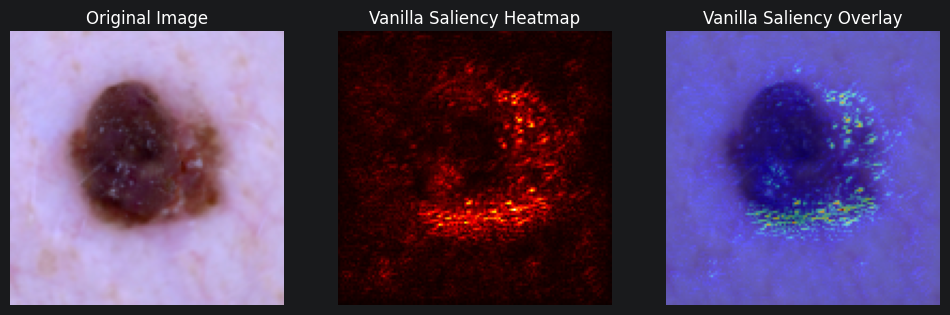

In [8]:
def vanilla_gradients(model, example_img, example_label):
    logits = model(example_img)
    score = logits[0, example_label]
    score.backward()

    vanilla_saliency = example_img.grad.data.abs().squeeze()
    vanilla_saliency = vanilla_saliency.max(dim=0)[0]
    vanilla_saliency = vanilla_saliency.detach().cpu().numpy()

    return vanilla_saliency

vanilla_saliency = vanilla_gradients(model, example_img, example_label)
show_heatmap(example_img, vanilla_saliency, "Vanilla Saliency")

- **Task (2 points)** SmoothGrad

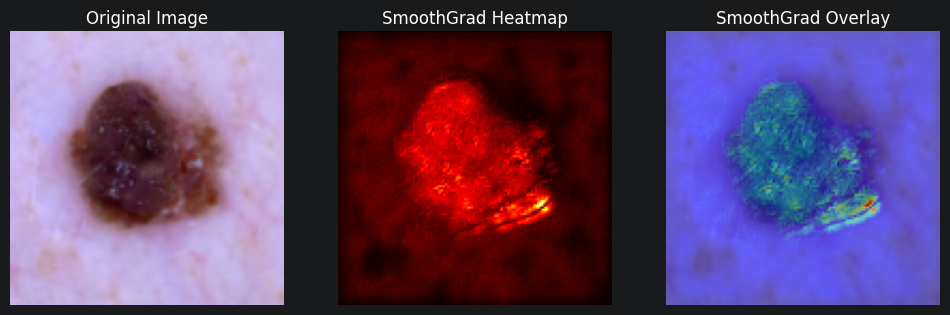

In [9]:
def smooth_grad(model, example_img, example_label, n_samples=200, stdev=0.2):
    model.zero_grad()
    grads = []
    for _ in range(n_samples):
        noise = torch.randn_like(example_img) * stdev
        noisy_image = (example_img + noise).clone().detach()
        noisy_image.requires_grad = True
        output = model(noisy_image)
        score = output[0, example_label]
        score.backward()
        grads.append(noisy_image.grad.data.cpu().numpy())

    # Convert list to array (n_samples, 1, 3, H, W)
    grads = np.array(grads)
    avg_grads = np.mean(grads, axis=0)[0]  # remove batch dim, shape (3,H,W)

    # Reduce channels to single 2D map
    saliency = np.abs(avg_grads).max(axis=0)  # shape (H,W)

    # Normalize
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)
    return saliency

smooth_saliency = smooth_grad(model, example_img, example_label, n_samples=100, stdev=0.2)
show_heatmap(example_img, smooth_saliency, "SmoothGrad")

- **Task (2 points)** GradCAM

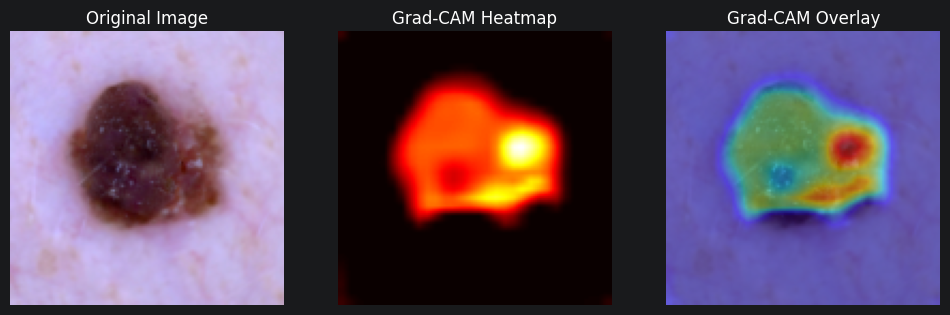

In [10]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, class_idx):
        self.model.zero_grad()
        output = self.model(x)
        score = output[0, class_idx]
        score.backward()

        weights = self.gradients.mean(dim=(2,3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(x.shape[2], x.shape[3]), mode='bilinear', align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

grad_cam = GradCAM(model, model.conv3)
cam = grad_cam(example_img, example_label)
show_heatmap(example_img, cam, "Grad-CAM")

- **Task (2 points)** LRP (below with Captum)

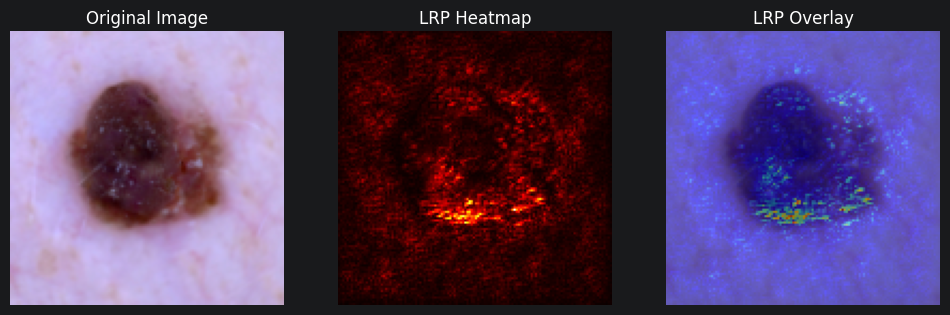

In [12]:
# LRP mit Captum
def lrp(model, example_img, example_label):
    lrp_attr = LRP(model)
    attributions = lrp_attr.attribute(example_img, target=example_label)
    lrp_saliency = attributions.data.abs().squeeze().cpu()
    lrp_saliency = lrp_saliency.max(dim=0)[0].numpy()
    lrp_saliency = (lrp_saliency - lrp_saliency.min()) / (lrp_saliency.max() - lrp_saliency.min() + 1e-8)
    return lrp_saliency

lrp_saliency = lrp(model, example_img, example_label)
show_heatmap(example_img, lrp_saliency, "LRP")

**Task (0.5 point)** Visualize the original image and all attribution maps side-by-side in a single figure

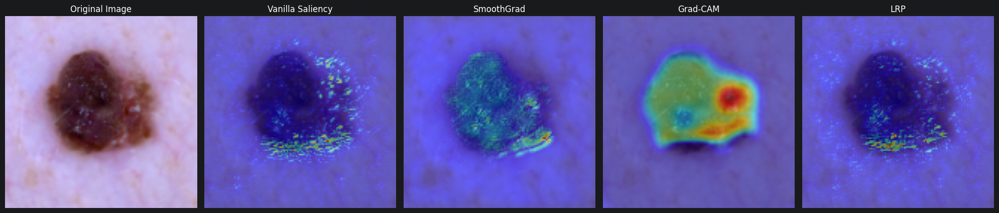

In [48]:
def plot_attribution_maps(image_index):
    # 1. Setup Data
    img, label = val_loader.dataset[image_index]
    img = img.unsqueeze(0).to(device)
    img.requires_grad = True
    label = label.item()

    # 2. Compute Attributions
    vanilla_sal = vanilla_gradients(model, img, label)
    smooth_sal = smooth_grad(model, img, label, n_samples=100, stdev=0.2)
    cam_sal = grad_cam(img, label)
    lrp_sal = lrp(model, img, label)

    # 3. Prepare Original Image for Plotting
    img_plot = img.detach().cpu().squeeze().permute(1, 2, 0)
    # Normalize to [0, 1] for imshow
    img_plot = (img_plot - img_plot.min()) / (img_plot.max() - img_plot.min() + 1e-8)

    # 4. Plot Side-by-Side
    plt.figure(figsize=(20, 5))

    titles = ["Original Image", "Vanilla Saliency", "SmoothGrad", "Grad-CAM", "LRP"]
    maps = [None, vanilla_sal, smooth_sal, cam_sal, lrp_sal]

    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(img_plot)
        if maps[i] is not None:
            # Overlay the heatmap
            plt.imshow(maps[i], cmap='jet', alpha=0.5)
        plt.title(titles[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()

plot_attribution_maps(rand_idx)

**Task (1 point)** Identify two missclassified samples and compute all 4 attribution maps for each.

Number of misclassified images in validation set: 17
Misclassified samples (index, true_label, pred_label):
Index: 2, True Label: 5, Predicted Label: 4


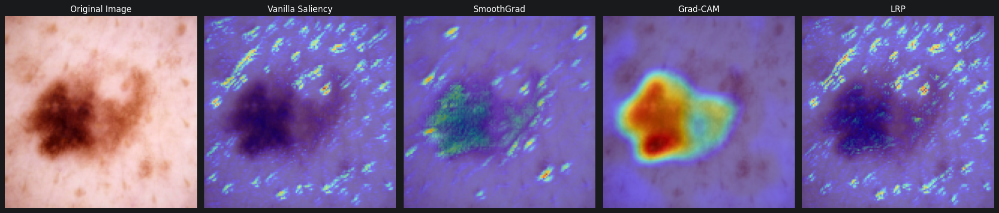

Index: 6, True Label: 5, Predicted Label: 4


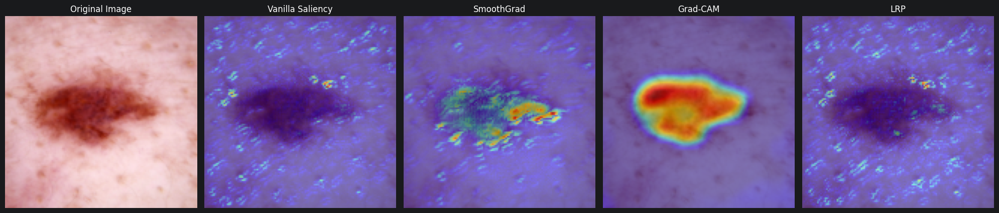

Index: 16, True Label: 4, Predicted Label: 2


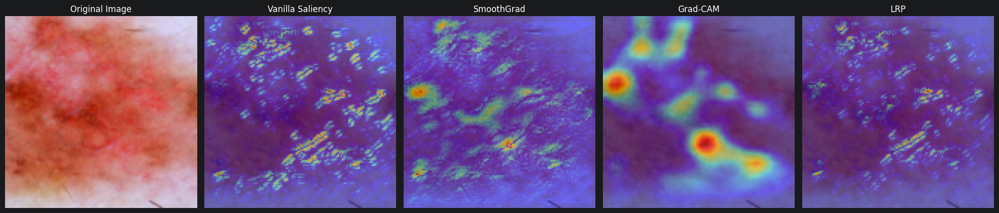

Index: 17, True Label: 5, Predicted Label: 6


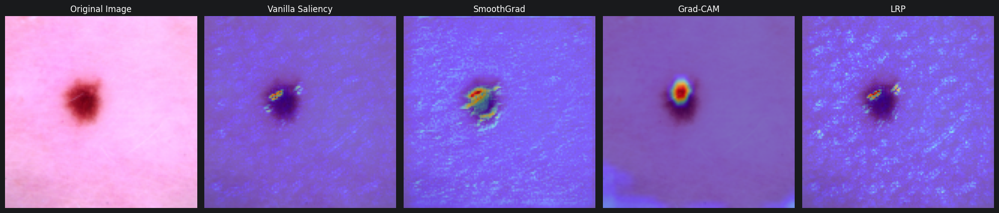

Index: 24, True Label: 2, Predicted Label: 4


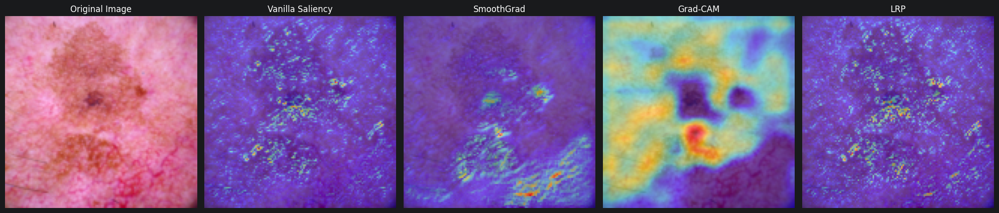

Index: 25, True Label: 6, Predicted Label: 1


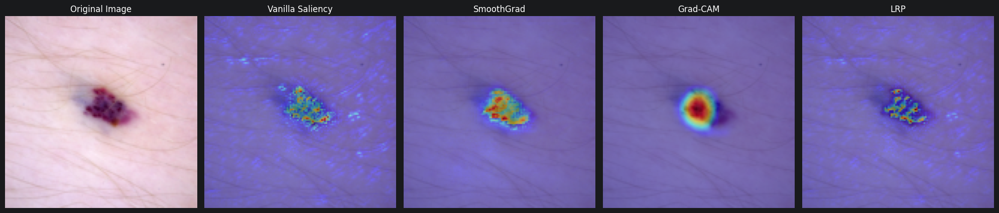

Index: 30, True Label: 5, Predicted Label: 1


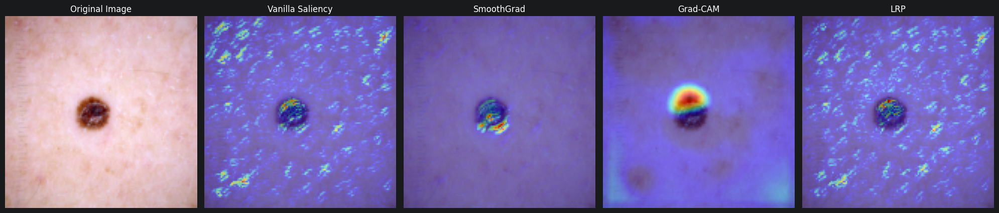

Index: 40, True Label: 5, Predicted Label: 4


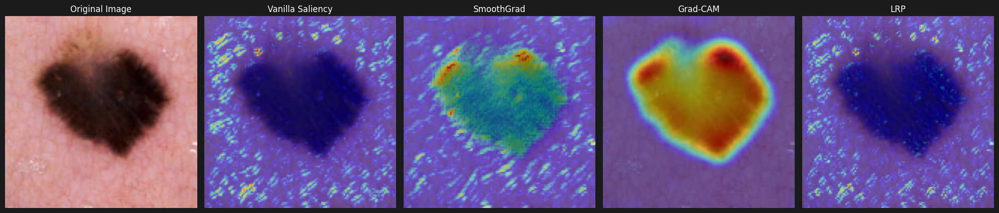

Index: 41, True Label: 1, Predicted Label: 2


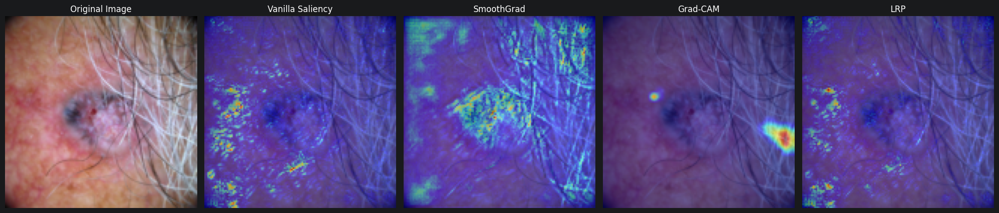

Index: 43, True Label: 1, Predicted Label: 2


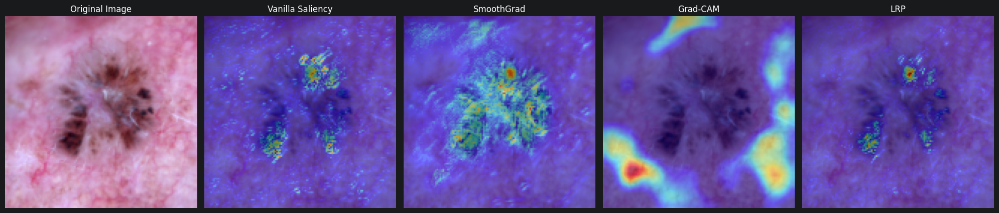

Index: 45, True Label: 1, Predicted Label: 0


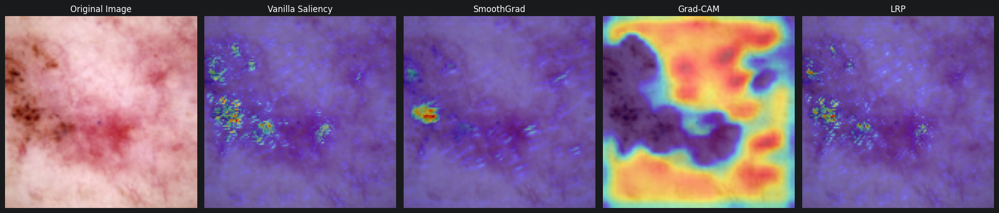

Index: 46, True Label: 2, Predicted Label: 1


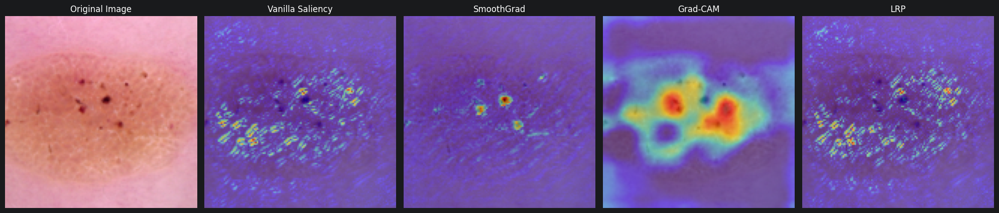

Index: 54, True Label: 5, Predicted Label: 1


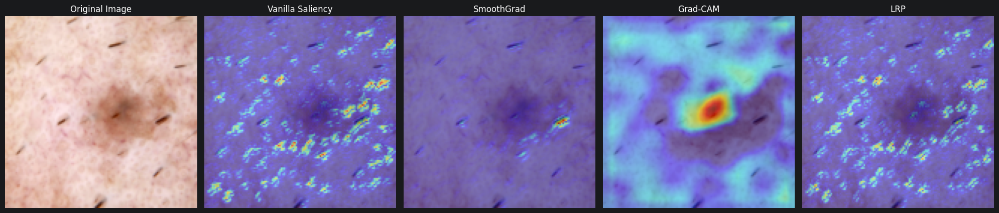

Index: 59, True Label: 5, Predicted Label: 2


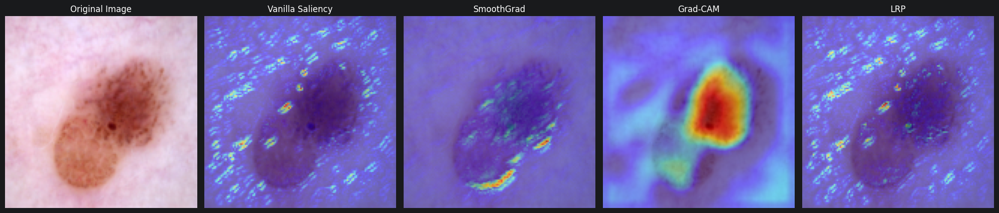

Index: 61, True Label: 5, Predicted Label: 4


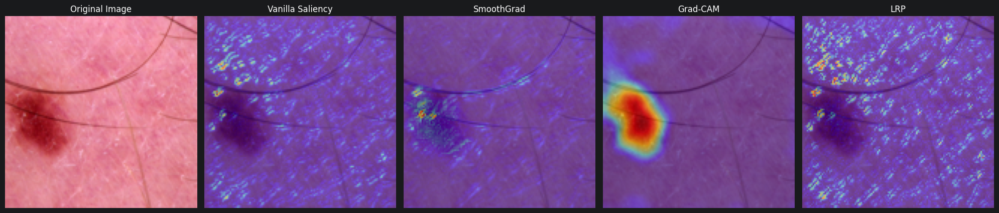

Index: 62, True Label: 1, Predicted Label: 0


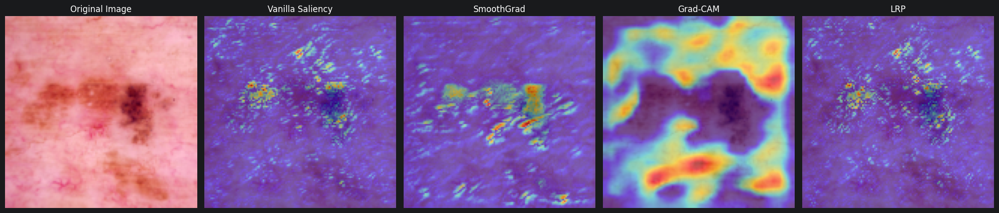

Index: 63, True Label: 2, Predicted Label: 5


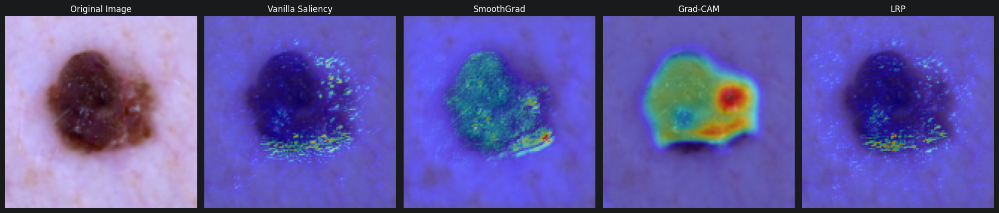

In [56]:
# identify misclassified samples from validation set
misclassified = [] # list of (index, true_label, pred_label)
model.eval()
with torch.no_grad():
    for idx, (imgs, lbls) in enumerate(val_loader):
        imgs, lbls = imgs.to(device), lbls.squeeze().long().to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        for i in range(imgs.size(0)):
            if preds[i] != lbls[i]:
                misclassified.append((idx * val_loader.batch_size + i, lbls[i].item(), preds[i].item()))
        if len(misclassified) >= 2:
            break

print(f"Number of misclassified images in validation set: {len(misclassified)}")
print("Misclassified samples (index, true_label, pred_label):")
for idx, true_lbl, pred_lbl in misclassified:
    print(f"Index: {idx}, True Label: {true_lbl}, Predicted Label: {pred_lbl}")
    plot_attribution_maps(idx)

**Task (1 point)** Quantify how much each attrbution method focuses on the object vs background

### Refined Analysis
While the attribution methods often successfully localize the primary lesion, the model’s reliability degrades in the presence of confounding features. When secondary blemishes, skin textures, or hairs are present, the saliency maps confirm that the model shifts its focus away from the clinically relevant lesion.

### Overview of Attribution Methods
These techniques are used to "peek inside the black box" of a neural network to see which pixels influenced the final classification.

| Method | Description | Strengths |
| :--- | :--- | :--- |
| **Original Image** | The raw dermoscopic input provided to the model. | Serves as the ground truth for visual comparison. |
| **Vanilla Saliency** | Computes the gradient of the output category with respect to the input pixels. | Provides a high-resolution map of which individual pixels have the steepest impact on the score. |
| **SmoothGrad** | Takes the average of multiple Vanilla Saliency maps generated by adding slight Gaussian noise to the image. | **Strength:** Significantly reduces "visual noise" and focuses on the most robust features, preventing "shimmery" or random artifacts. |
| **Grad-CAM** | Uses the gradients flowing into the final convolutional layer to produce a coarse localization map. | **Strength:** Excellent at identifying the broad "object-level" region the model is looking at; less sensitive to pixel-level noise. |
| **LRP** | **Layer-wise Relevance Propagation** redistributes the prediction score backward through the layers using specific rules. | **Strength:** Maintains a "conservation principle," ensuring the total relevance score equals the output, highlighting specific textural features. |
